In [1]:
import pandas as pd
import joblib
import os
from dotenv import load_dotenv
from conformist import FNRCoP, PredictionDataset, ValidationTrial

In [2]:
OUTPUT_DIR = "/home/mariya/Development/pallas/reports/output/cp/rf_DNAm_20260606_193214"
# Create the output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
# Load the model
RF_MODEL_PATH = "/home/mariya/Data/pallas/models/rf_DNAm_20260606_193214/rf_model.joblib"
rf = joblib.load(RF_MODEL_PATH)

In [4]:
# Load test data
X_TEST_CSV_PATH = "/home/mariya/Data/pallas/mlomix_datasets/test-dnam/features.dnam.csv"
Y_TEST_TSV_PATH = "/home/mariya/Data/pallas/mlomix_datasets/test-dnam/labels.csv"
X_test = pd.read_csv(X_TEST_CSV_PATH, index_col=0)
y_test = pd.read_csv(Y_TEST_TSV_PATH, index_col=0, sep="\t").squeeze()
X_test.shape, y_test.shape

((333, 1186), (333, 0))

In [5]:
PREDS_CAL_CSV_PATH = "/home/mariya/Development/pallas/reports/output/predictions/rf_DNAm_20260606_193214/cal-dnam/cal-dnam_predictions.csv"
# Load calibration predictions
preds_cal = pd.read_csv(PREDS_CAL_CSV_PATH, index_col=0)
preds_cal

,true_label,predicted_label,"AML, APL-PML::RARA","AML, CBFA2T3::GLIS2","AML, CBFB::MYH11","AML, CEBPAalt","AML, DEK::NUP214","AML, ETV6-r","AML, FUS::ERG","AML, KAT6A-r",...,"B-ALL, KMT2A-r","B-ALL, MEF2D-r","B-ALL, PAX5 P80R","B-ALL, PAX5alt","B-ALL, TCF3::PBX1","B-ALL, ZNF384-r","B-ALL, high hyperdiploid","B-ALL, iAMP21",Non-leukemic,T-ALL
id,,,,,,,,,,,,,,,,,,,,,
ALL_1252,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.001068,0.000379,0.001520,0.000000,0.002302,0.000000,0.000000,...,0.000890,0.0,0.000000,0.011719,0.000000,0.002338,0.906781,0.000000,0.000662,0.000783
ALL_1281,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1",0.004025,0.025354,0.021399,0.025153,0.011370,0.014264,0.000327,0.002749,...,0.009352,0.0,0.000000,0.010118,0.008988,0.000083,0.059834,0.001883,0.032456,0.065007
ALL_1290,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1",0.000000,0.000000,0.001221,0.001757,0.000000,0.000000,0.000000,0.000000,...,0.002197,0.0,0.000000,0.005870,0.000000,0.005251,0.012083,0.000000,0.000000,0.000000
ALL_1362,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000250,0.000899,0.000040,0.000058,0.000069,0.000000,0.000000,...,0.000034,0.0,0.000000,0.005375,0.000014,0.000049,0.968665,0.001940,0.000015,0.000010
ALL_1378,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000250,0.005497,0.001359,0.000058,0.000501,0.000000,0.000000,...,0.000144,0.0,0.003949,0.002346,0.000014,0.000510,0.875098,0.001940,0.000015,0.000010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-AB-2990,"AML, NPM1alt","AML, NPM1alt",0.016597,0.014615,0.004013,0.008331,0.001500,0.023458,0.002000,0.000315,...,0.007345,0.0,0.000000,0.000484,0.000455,0.000051,0.001073,0.000000,0.006635,0.002395
TCGA-AB-2998,"AML, APL-PML::RARA","AML, APL-PML::RARA",0.903384,0.005348,0.002068,0.010270,0.000805,0.000627,0.000000,0.000118,...,0.001838,0.0,0.000000,0.000369,0.000000,0.000000,0.000472,0.000000,0.004763,0.003583
TCGA-AB-2999,"AML, APL-PML::RARA","AML, APL-PML::RARA",0.964685,0.000478,0.001006,0.002981,0.000130,0.000335,0.000000,0.000000,...,0.000147,0.0,0.000000,0.000000,0.000243,0.000000,0.000134,0.000000,0.002450,0.006098


In [6]:
PREDS_TEST_CSV_PATH = "/home/mariya/Development/pallas/reports/output/predictions/rf_DNAm_20260606_193214/test-dnam/test-dnam_predictions.csv"
# Load test predictions
preds_test = pd.read_csv(PREDS_TEST_CSV_PATH, index_col=0)
preds_test

,true_label,predicted_label,"AML, APL-PML::RARA","AML, CBFA2T3::GLIS2","AML, CBFB::MYH11","AML, CEBPAalt","AML, DEK::NUP214","AML, ETV6-r","AML, FUS::ERG","AML, KAT6A-r",...,"B-ALL, KMT2A-r","B-ALL, MEF2D-r","B-ALL, PAX5 P80R","B-ALL, PAX5alt","B-ALL, TCF3::PBX1","B-ALL, ZNF384-r","B-ALL, high hyperdiploid","B-ALL, iAMP21",Non-leukemic,T-ALL
id,,,,,,,,,,,,,,,,,,,,,
ALL_1381,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1",0.000000,0.000000,0.001218,0.001831,0.000000,0.000000,0.000000,0.000000,...,0.004000,0.000000,0.000000,0.004000,0.000000,0.005623,0.003864,0.000000,0.000000,0.000000
ALL_1386,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.000000,0.000250,0.001317,0.000806,0.000156,0.000501,0.000000,0.000000,...,0.006948,0.000000,0.001949,0.016515,0.000086,0.000510,0.877983,0.002001,0.000537,0.000061
ALL_1391,"B-ALL, high hyperdiploid","B-ALL, high hyperdiploid",0.004364,0.009153,0.012868,0.010147,0.003780,0.013241,0.000963,0.000909,...,0.015197,0.000000,0.000664,0.030152,0.004088,0.001327,0.695098,0.000197,0.009174,0.007322
ALL_438,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1",0.000000,0.000000,0.003608,0.001831,0.000000,0.001723,0.000000,0.000000,...,0.000000,0.001958,0.009941,0.002308,0.000000,0.003472,0.016320,0.003860,0.000000,0.000000
AML_002,"AML, KMT2A-r","AML, KMT2A-r",0.000652,0.010549,0.022352,0.023344,0.031702,0.007491,0.010032,0.026989,...,0.043741,0.000000,0.000115,0.010722,0.013439,0.002210,0.019054,0.004000,0.008045,0.004585
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-AB-2826,"AML, NPM1alt","AML, NPM1alt",0.003333,0.027222,0.009029,0.016880,0.007888,0.011547,0.000556,0.002252,...,0.005281,0.000000,0.000000,0.000310,0.001145,0.000134,0.002569,0.000193,0.011012,0.002359
TCGA-AB-2836,"AML, NPM1alt","AML, NPM1alt",0.000333,0.003099,0.001400,0.002076,0.002337,0.005966,0.000000,0.000254,...,0.000454,0.000000,0.000115,0.000245,0.000398,0.000049,0.000400,0.000000,0.000559,0.001628
TCGA-AB-2848,"AML, NPM1alt","AML, NPM1alt",0.000286,0.006310,0.001252,0.005829,0.001637,0.011461,0.000000,0.000254,...,0.000649,0.000000,0.000115,0.000245,0.000284,0.000049,0.000364,0.000000,0.000684,0.001651


In [7]:
# Read in formatted predictions
calpd = PredictionDataset(predictions_csv=PREDS_CAL_CSV_PATH, dataset_name='cal')
testpd = PredictionDataset(predictions_csv=PREDS_TEST_CSV_PATH, dataset_name='test')
calpd, testpd

(<conformist.prediction_dataset.PredictionDataset at 0x7b328378f2e0>,
 <conformist.prediction_dataset.PredictionDataset at 0x7b328378ece0>)

In [8]:
# First, check for rare classes in the calibration dataset
class_counts = calpd.df['true_label'].value_counts()
print("Class distribution in calibration data:")
print(class_counts)

# Filter out rare classes (optional)
MIN_SAMPLES = 5  # Minimum samples required per class
rare_classes = class_counts[class_counts < MIN_SAMPLES].index.tolist()
if rare_classes:
    print(f"Warning: Found {len(rare_classes)} classes with fewer than {MIN_SAMPLES} samples: {rare_classes}")
    print("These rare classes may cause numerical issues in conformal prediction")

# Modify alpha to be more conservative when working with small datasets
# Smaller alpha -> larger prediction sets -> more conservative
ALPHA = 0.05  # Try a smaller alpha (was 0.1)

mcp = FNRCoP(calpd, alpha=ALPHA)
mcp.calibrate()

# # Try with more regularization
# mcp = FNRCoP(calpd, alpha=ALPHA)

# # Use try/except to handle potential errors
# try:
#     trial = mcp.do_validation_trial(n_runs=10)
#     trial.run_reports(OUTPUT_DIR)
# except ValueError as e:
#     print(f"Error during conformal calibration: {e}")
#     print("Trying with even more conservative settings...")

#     # Try with even smaller alpha as a fallback
#     mcp = FNRCoP(calpd, alpha=0.01)
#     trial = mcp.do_validation_trial(n_runs=5)  # Fewer runs as a fallback
#     trial.run_reports(OUTPUT_DIR)

Class distribution in calibration data:
true_label
AML, KMT2A-r                52
B-ALL, high hyperdiploid    49
B-ALL, ETV6::RUNX1          43
AML, RUNX1::RUNX1T1         37
AML, NPM1alt                28
AML, CBFB::MYH11            27
Non-leukemic                21
T-ALL                       16
AML, NUP98-r                15
AML, CEBPAalt               11
B-ALL, PAX5alt              10
B-ALL, KMT2A-r               9
AML, DEK::NUP214             8
B-ALL, BCR::ABL1             8
AML, APL-PML::RARA           7
B-ALL, iAMP21                7
AML, ETV6-r                  7
B-ALL, BCR::ABL1-like        6
B-ALL, ETV6::RUNX1-like      6
B-ALL, ZNF384-r              6
AML, CBFA2T3::GLIS2          5
B-ALL, DUX4-r                5
B-ALL, TCF3::PBX1            5
B-ALL, MEF2D-r               3
AML, PICALM::MLLT10          3
AML, KAT6A-r                 3
B-ALL, PAX5 P80R             2
AML, FUS::ERG                2
Name: count, dtype: int64
These rare classes may cause numerical issues in confor

[np.float64(1.000000082740371e-10), np.float64(0.10000000008999999), np.float64(0.02500000009749992), np.float64(0.02500000009749992), np.float64(0.02500000009749992), np.float64(0.05000000009499994), np.float64(0.02500000009749992), np.float64(0.05000000009499994), np.float64(0.07500000009249985), np.float64(0.02500000009749992), np.float64(0.1250000000875), np.float64(0.07500000009249985), np.float64(0.10000000008999999), np.float64(0.05000000009499994), np.float64(0.07500000009250007), np.float64(0.05000000009499994), np.float64(0.02500000009749992), np.float64(0.05000000009499994), np.float64(0.02500000009749992), np.float64(0.07500000009249985), np.float64(0.02500000009749992), np.float64(0.07500000009249985), np.float64(0.10000000008999999), np.float64(1.000000082740371e-10), np.float64(0.02500000009749992), np.float64(0.05000000009499994), np.float64(0.05000000009499994), np.float64(0.12500000008750012), np.float64(0.02500000009749992), np.float64(1.000000082740371e-10), np.floa

<Figure size 400x300 with 0 Axes>

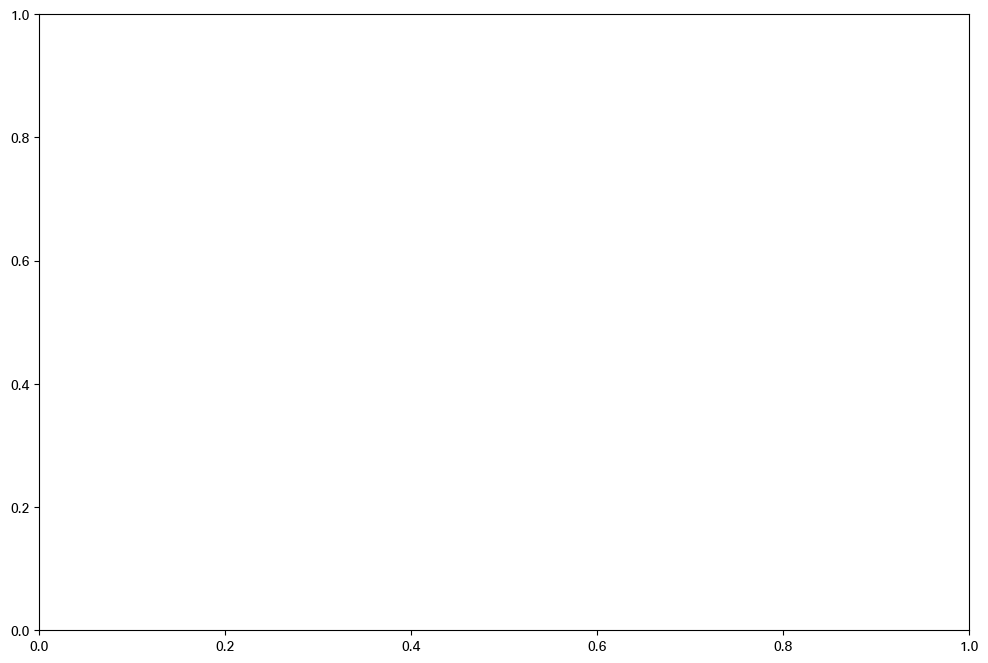

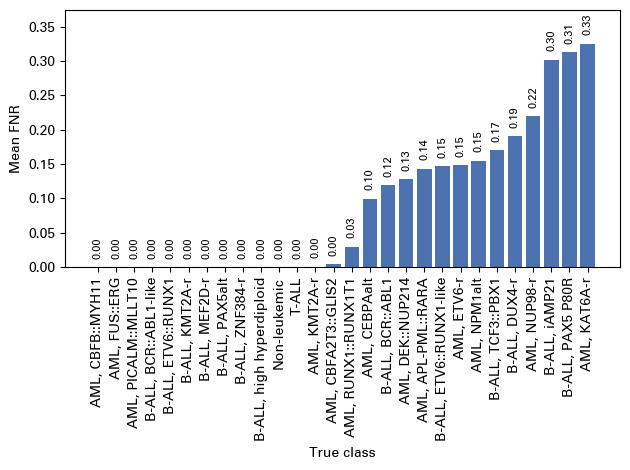

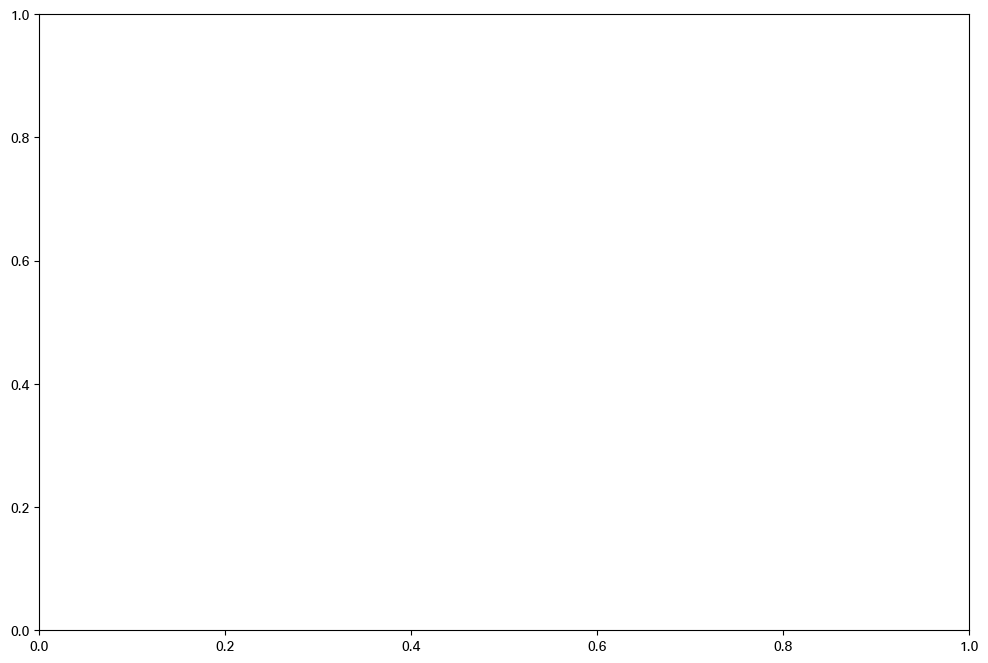

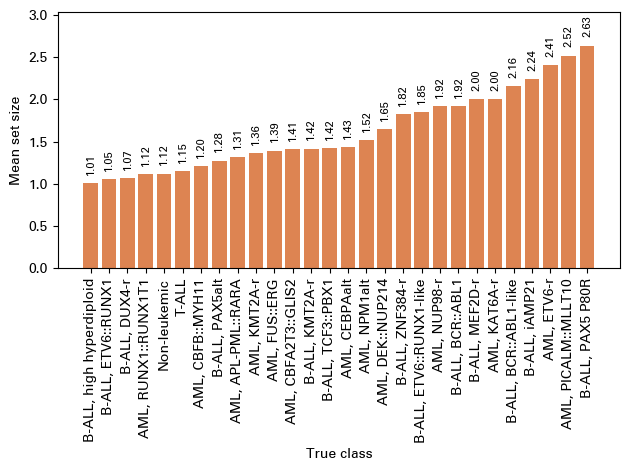

In [9]:
ALPHA=0.05
N_RUNS=1000 # replace with 1000

# Validation trial and reports
mcp = FNRCoP(calpd, alpha=ALPHA)
trial = mcp.do_validation_trial(n_runs=N_RUNS)
trial.run_reports(OUTPUT_DIR)


/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

Saving upset plot to /home/mariya/Development/pallas/reports/output/cp/rf_DNAm_20260606_193214/FNRCoP/2026-06-24_21-13-12/upset_plot.pdf


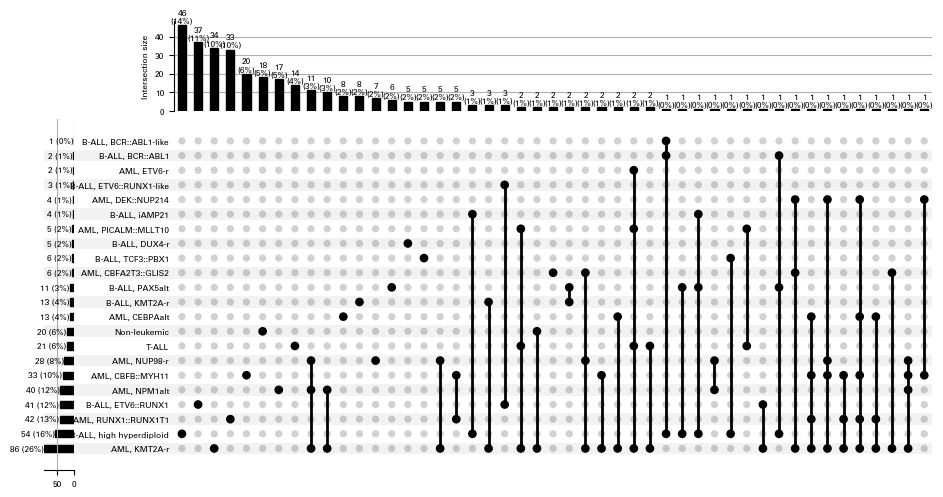

In [10]:
formatted_predictions = mcp.predict(testpd,
                                    OUTPUT_DIR)